In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, TensorDataset
import torch.optim as optim
import numpy as np
import math
from sklearn.metrics import r2_score

import matplotlib.pyplot as plt

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

print(device)

#%matplotlib widget

PATH = "results/logs"

cuda:0


Load loss and R^2 value of the models trained

In [3]:
L_train = []
L_Val = []
R2_train = []
R2_val = []

numero_modelli = 6
density = 5
for i in range(0,numero_modelli):
    data = np.genfromtxt(PATH + f"modello{i+1}_epoche=150.txt", skip_footer=1, delimiter='\t', skip_header=1, usecols=range(1,5))

    L_train.append(data[:,0])
    L_Val.append(data[:,1])
    R2_train.append(data[:,2])
    R2_val.append(data[:,3])


n_epoch = len(L_train[0])

x = np.linspace(1,n_epoch,n_epoch)

Function used to generate graph

In [5]:
def grafico(dati,filename = "null", scala='log', density = 1, xlabel = r'MSE', location = 3):
    fig, axs = plt.subplots(figsize=(10,8))
  

    axs.plot(x[::density], dati[0][::density],c='b',marker="^",ls='--',label='M1',fillstyle='none')
    axs.plot(x[::density], dati[1][::density],c='g',marker=(8,2,0),ls='--',label='M2')
    axs.plot(x[::density], dati[2][::density],c='k',ls='-',label='M3')
    axs.plot(x[::density], dati[3][::density],c='r',marker="v",ls='-',label='M4')
    axs.plot(x[::density], dati[4][::density],c='m',marker="o",ls='--',label='M5',fillstyle='none')
    axs.plot(x[::density], dati[5][::density],c='k',marker="+",ls=':',label='M6')

    axs.set_yscale(scala)
    #axs.legend(loc=location)
    axs.set_xlabel(r'$N_e$', fontsize= 25)
    axs.set_ylabel(xlabel, fontsize= 25)


    plt.legend(loc=location)
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['Arial']
    plt.rcParams['font.size'] = 20
    plt.savefig(f"../../TESI UFFICIALE/Immagini/Grafici/Analisi modelli/{filename}.png", dpi=300)


Plot value of MSE for all the models (respectively training and validation)

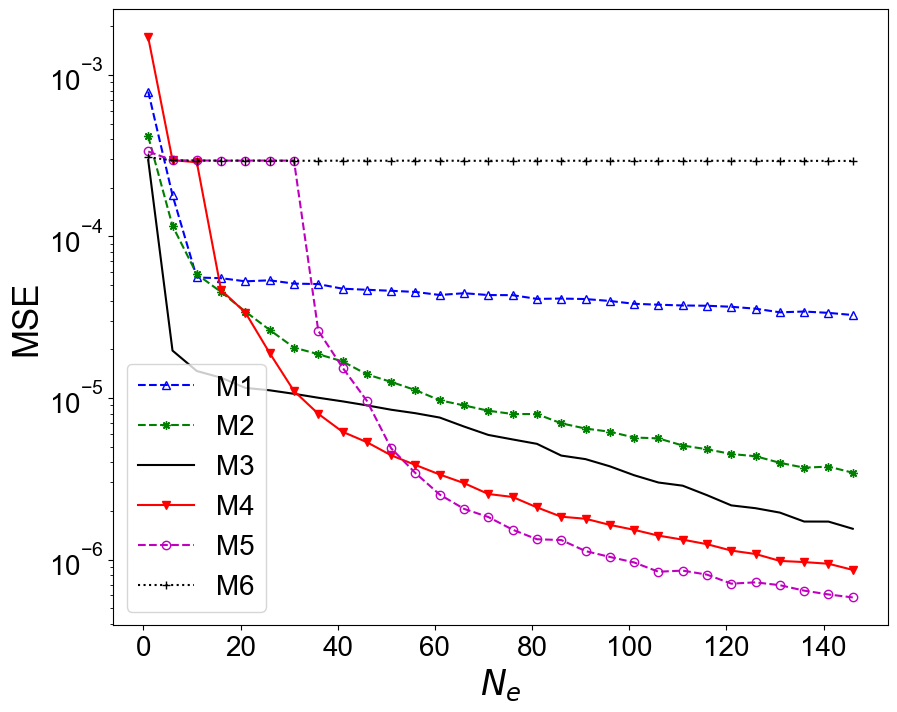

In [6]:
grafico(L_train,"MSE_TRAIN", density=5, scala="log")

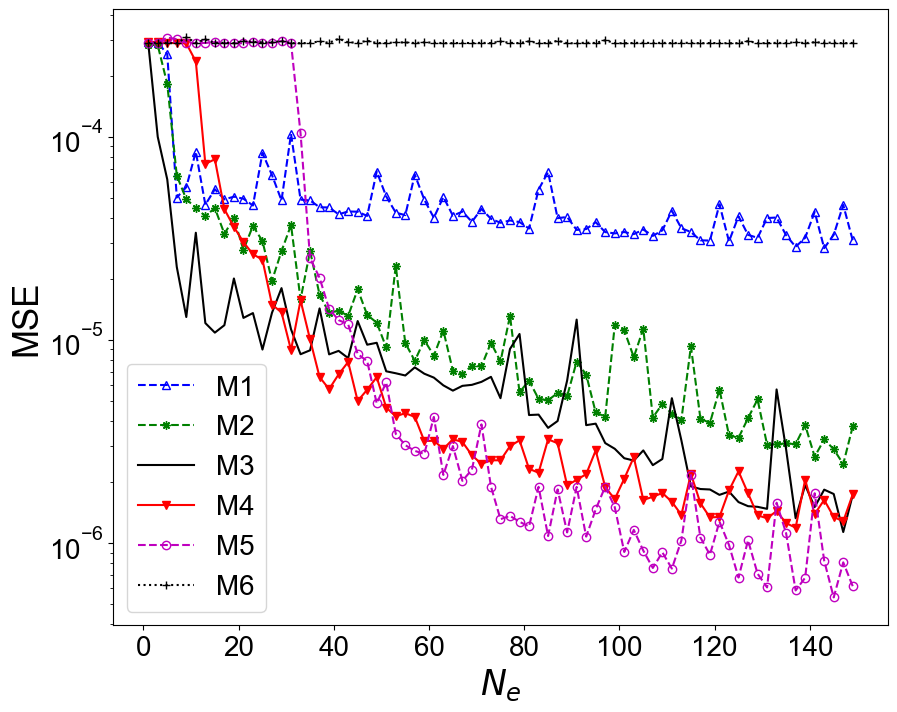

In [7]:
grafico(L_Val,filename="MSE_VAL", density=2)

Plot value of R^2 for all the models (respectively training and validation)

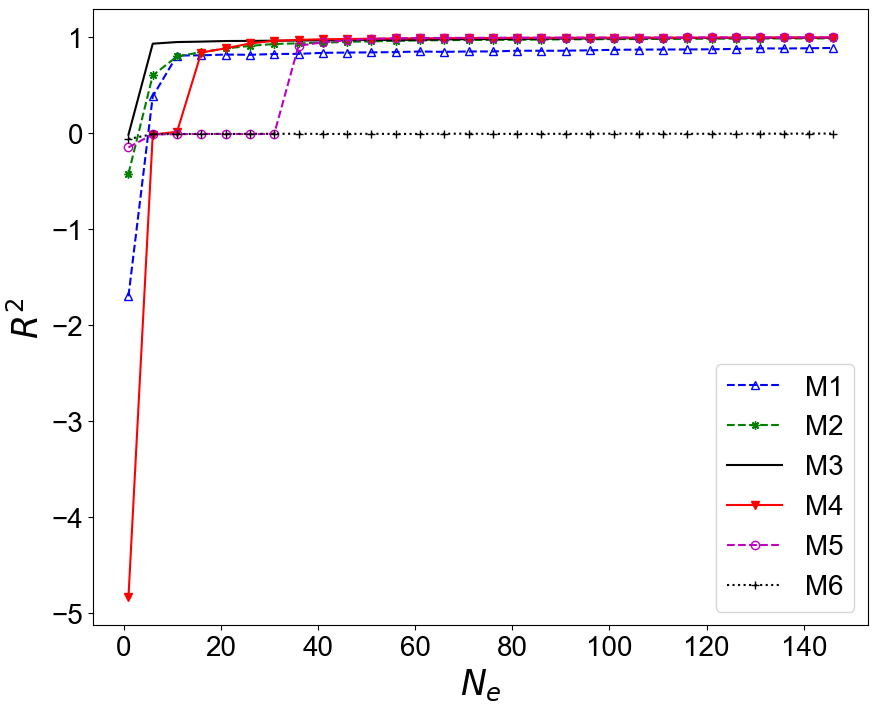

In [8]:
grafico(R2_train, filename="R2_TRAIN", density=5, scala="linear", xlabel = r"$R^2$", location=4)

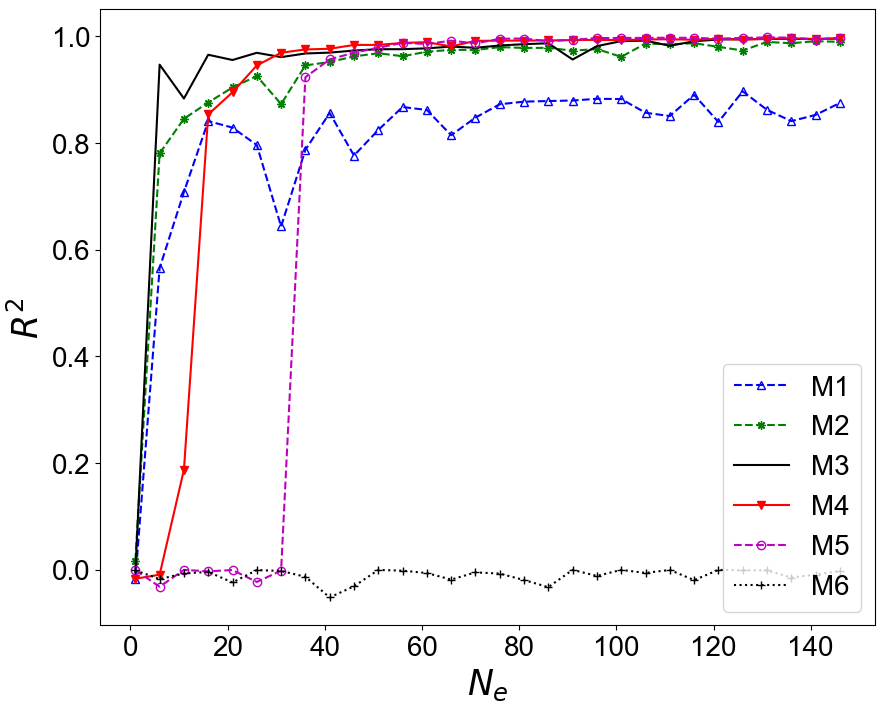

In [9]:
grafico(R2_val, filename="R2_VAL", density=5, scala="linear", xlabel = r"$R^2$", location=4)

Function which put together validation and training loss values

In [2]:
# data = np.genfromtxt(PATH + f"modello2_epoche=50.txt", skip_footer=1, delimiter='\t', skip_header=1, usecols=range(1,5))
# MSE_train = data[:,0]
# MSE_val = data[:,1]
# R2_train = data[:,2]
# R2_val = data[:,3]

x = np.linspace(1,50, 50)


def grafico_LR(dati,filename = "null", scala='log', density = 1, xlabel = r'MSE', location = 3):
    fig, ax = plt.subplots(figsize = (10,8))

    ax.plot(x[::density], dati[0][::density],c='r',marker="v",ls='-',label='Addestramento',fillstyle='none')
    ax.plot(x[::density], dati[1][::density],c='b',marker="^",ls='--',label='Validazione')
    

    ax.set_yscale(scala)
    #axs.legend(loc=location)
    ax.set_xlabel(r'$N_e$', fontsize= 25)
    ax.set_ylabel(xlabel, fontsize= 25)
    #ax.set_ylim(top=1)
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['Arial']
    plt.rcParams['font.size'] = 20
    plt.legend(loc=location)
    plt.savefig(f"../../TESI UFFICIALE/Immagini/Grafici/Analisi modelli/{filename}.png", dpi=300)

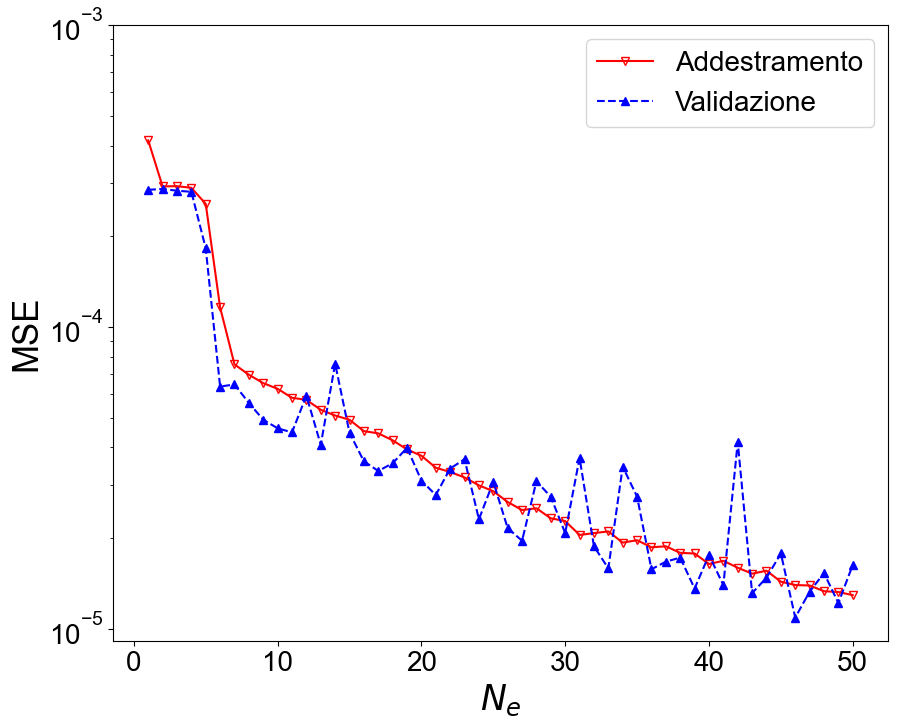

In [87]:
grafico_LR([L_train[1][:50], L_Val[1][:50]], filename="MSE_LR=1e-4", location=1, scala="log")

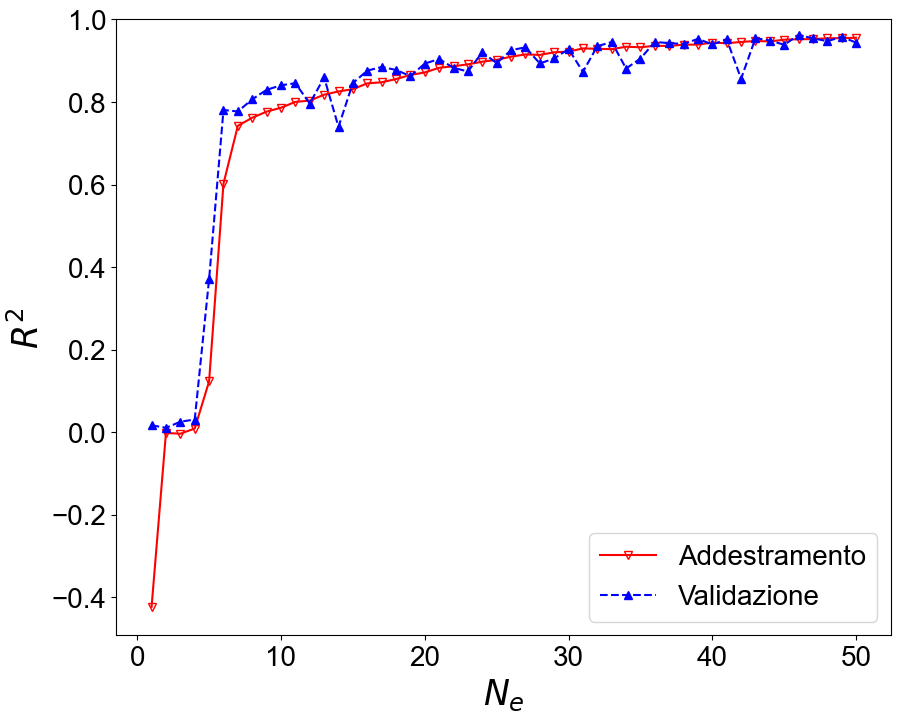

In [92]:
grafico_LR([R2_train[1][:50], R2_val[1][:50]], filename="R2_LR=1e-4", location=4, scala="linear", xlabel=r'$R^2$')

Simple plot of training times

<function matplotlib.pyplot.show(close=None, block=None)>

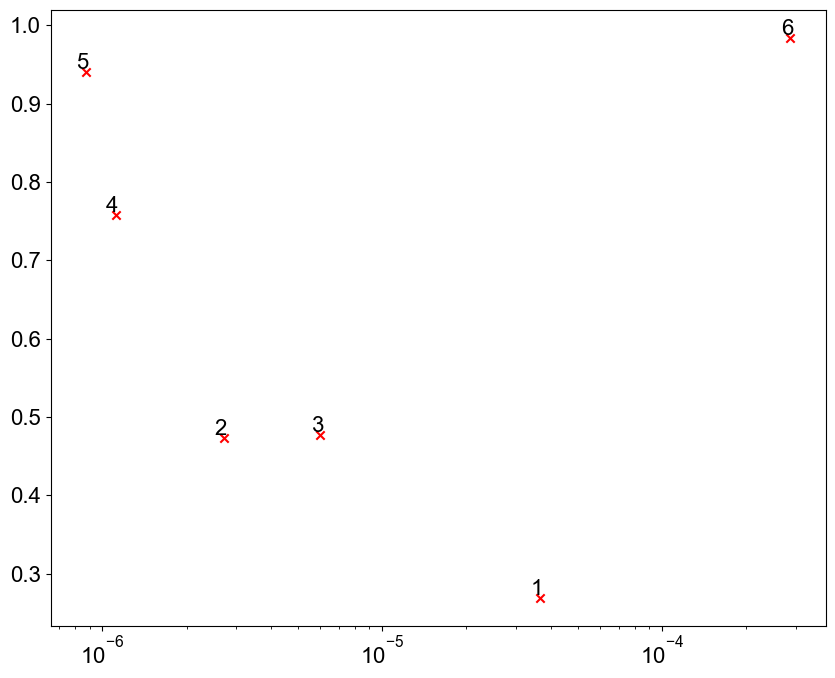

In [ ]:
tempi = np.array([967.9739503860474, 1704.8225364685059, 1716.9875581264496, 2728.3438572883606, 3385.7983734607697, 3541.57030916214])
tempi = tempi / 3600

test_data = np.loadtxt("Modello 1/test_modelli.txt", skiprows=1)

MSE_test = test_data[:,0]
R2_test = test_data[:,1]

legenda = []
for i in range(0,6):
    legenda.append(f"Modello{i}")

fig, ax = plt.subplots(figsize = (10,8))
ax.scatter(MSE_test, tempi, marker='x', color = 'red')
ax.set_xscale('log')

for i in range(0,6):
    ax.annotate(f"{i+1}", (MSE_test[i], tempi[i]), textcoords = 'offset points', xytext=(2,2))
plt.show